# F&B Sales Analytics: аналіз продажів мережі кав'ярень

**Індонезія · 3 торгові точки · січень–вересень 2025**

## Про проєкт
Мережа кав'ярень у `SHOP001`, `SHOP002` і `SHOP003` зберігає кожен продаж у касовій системі (POS). У цьому ноутбуці я аналізую ці дані: **53 820 чеків, 61 973 продані позиції, 96 товарів у меню**. Валюта: індонезійська рупія (IDR).

Мета: зрозуміти, **де, коли і на чому** бізнес заробляє, і запропонувати кілька ідей для зростання.

## На які питання відповідає аналіз
1. Скільки заробляє мережа і який середній чек?
2. Чим відрізняються три заклади?
3. Як змінювалися продажі по місяцях і що сталося в квітні?
4. У які дні й години найбільше покупців?
5. Які категорії та продукти приносять найбільше доходу?
6. Як працює програма лояльності?
7. Як клієнти платять?
8. Що купують разом в одному чеку?

## Дані
| Файл | Що в ньому |
|---|---|
| `Transactions.csv` | один рядок = один чек (заклад, дата, час, сума, список товарів, спосіб оплати) |
| `Products.csv` | довідник меню (назва, варіант, категорія, ціна) |

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


BLUE = '#1F4E79'
LIGHT_BLUE = '#8FB8DE'
ORANGE = '#E8742A'
GREY = '#9A9A9A'
GREEN = '#2E8B57'
RED = '#C0392B'

# кожен заклад має свій колір у всіх графіках
OUTLET_COLORS = {'SHOP001': BLUE, 'SHOP002': ORANGE, 'SHOP003': LIGHT_BLUE}

In [18]:
# шукаю папку з файлами: поруч із ноутбуком або в ../data/
DATA_DIR = None
for folder in ['../data/', 'data/', '']:
    if os.path.exists(folder + 'Transactions.csv'):
        DATA_DIR = folder
        break
if DATA_DIR is None:
    raise FileNotFoundError('Не знайшов Transactions.csv. Покладіть файлиф в папку data/ або поруч із ноутбуком.')

products = pd.read_csv(DATA_DIR + 'Products.csv')
transactions = pd.read_csv(DATA_DIR + 'Transactions.csv')

print(f'Products: {products.shape[0]} рядків, {products.shape[1]} колонок')
print(f'Transactions: {transactions.shape[0]} рядків, {transactions.shape[1]} колонок')
display(products.head(3))
display(transactions.head(3))

Products: 96 рядків, 6 колонок
Transactions: 53820 рядків, 11 колонок


,ProductId,ProductName,Variant,Category,Price,Description
0,1,Add on Aren,-,Add on,0,"Tambahan sirup gula aren murni, memberikan ras..."
1,2,Add on Simple Syrup,-,Add on,0,Tambahan sirup gula sederhana (air dan gula) s...
2,3,Air Mineral,-,Other,5000,Air minum murni dalam kemasan


,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
0,SHOP001,2025-01-02,07:01:05,20720.721,2279.279,23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0
1,SHOP001,2025-01-02,07:04:11,18018.018,1981.982,20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0
2,SHOP002,2025-01-02,07:10:46,39639.640,4360.360,44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0


In [19]:
# перетворюю дату й час та додаю зручні колонки
transactions['Date'] = pd.to_datetime(transactions['Date'])
transactions['Month'] = transactions['Date'].dt.to_period('M').astype(str)
transactions['Weekday_num'] = transactions['Date'].dt.dayofweek          # 0 = понеділок
transactions['Hour'] = pd.to_datetime(transactions['Time'], format='%H:%M:%S').dt.hour

# перевірки якості
print('Пропуски в Products:', products.isna().sum().sum())
print('Пропуски в Transactions:', transactions.isna().sum().sum())
print('Дублікати номерів чеків:', transactions['ReceiptNumber'].duplicated().sum())
print('Від\'ємні суми чеків:', (transactions['TotalAmount'] < 0).sum())
print('Чеки з нульовою сумою:', (transactions['TotalAmount'] == 0).sum())
print('Заклади:', sorted(transactions['Outlet'].unique()))
print('Способи оплати:', sorted(transactions['PaymentMethod'].unique()))
print('Період:', transactions['Date'].min().date(), '—', transactions['Date'].max().date())

Пропуски в Products: 0
Пропуски в Transactions: 0
Дублікати номерів чеків: 0
Від'ємні суми чеків: 0
Чеки з нульовою сумою: 1733
Заклади: ['SHOP001', 'SHOP002', 'SHOP003']
Способи оплати: ['BCA', 'Cash', 'GoFood']
Період: 2025-01-02 — 2025-09-30


C:\Users\Дмитро\AppData\Local\Temp\ipykernel_25596\863099258.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  transactions['Weekday_num'] = transactions['Date'].dt.dayofweek          # 0 = понеділок


 Чеки з **нульовою сумою** не помилка: це чеки, оплачені програмою лояльності (клієнт отримує позицію безкоштовно). Їх я розберу в окремому розділі.

## 3. Підготовка таблиці проданих позицій
У чеку всі товари записані в одному полі `Items` через кому, наприклад `BLACK (Arabica), Americano (Hot Arabica)`. Щоб рахувати продажі по продуктах і категоріях, я:
1. складаю повну назву товару в довіднику (`Назва (Варіант)`),
2. розділяю список товарів у чеку на окремі рядки (`explode`),
3. приєдную довідник, щоб отримати категорію та ціну.

In [20]:
# повна назва товару, як вона записана в чеках
products['FullName'] = np.where(
    products['Variant'] == '-',
    products['ProductName'],
    products['ProductName'] + ' (' + products['Variant'] + ')'
)

# один рядок = одна позиція в чеку
items_df = transactions[['ReceiptNumber', 'Outlet', 'Month', 'PaymentMethod', 'UseLoyaltyCard', 'TotalItem', 'Items']].copy()
items_df['Item'] = items_df['Items'].str.split(', ')
items_df = items_df.explode('Item')

# приєдную категорію та ціну з довідника
items_df = items_df.merge(
    products[['ProductId', 'FullName', 'ProductName', 'Category', 'Price']],
    left_on='Item', right_on='FullName', how='left'
)

# якщо клієнт платив карткою лояльності, позиція безкоштовна
items_df['Revenue'] = np.where(items_df['UseLoyaltyCard'] == 1, 0, items_df['Price'])
items_df['Loyalty_Discount'] = np.where(items_df['UseLoyaltyCard'] == 1, items_df['Price'], 0)

print(f'Позицій у таблиці: {len(items_df):,} (сума TotalItem у чеках: {transactions["TotalItem"].sum():,})')
print(f'Товарів, яких не знайшли в довіднику: {items_df["ProductId"].isna().sum()}')

Позицій у таблиці: 61,973 (сума TotalItem у чеках: 61,973)
Товарів, яких не знайшли в довіднику: 0


### Перевірка: чи збігаються гроші
Найважливіше правило аналітика: **цифри з різних джерел мають сходитися**. Порівнюю дохід, який я порахував з окремих товарів, із сумами в заголовках чеків.

In [21]:
income_from_items = items_df['Revenue'].sum()
income_from_receipts = transactions['TotalAmount'].sum()
difference = income_from_items - income_from_receipts

print(f'Дохід за позиціями (ціни з довідника):  {income_from_items:,.0f} IDR')
print(f'Дохід за чеками (поле TotalAmount):     {income_from_receipts:,.0f} IDR')
print(f'Різниця:                                {difference:,.0f} IDR')

if difference == 0:
    print('Суми збігаються, розбивка чеків на позиції виконана правильно.')
else:
    print('Увага: є розбіжність, потрібно перевірити назви товарів у чеках.')

Дохід за позиціями (ціни з довідника):  1,315,276,000 IDR
Дохід за чеками (поле TotalAmount):     1,315,276,000 IDR
Різниця:                                0 IDR
Суми збігаються, розбивка чеків на позиції виконана правильно.


**Висновок:** суми збігаються до рупії, тож усі наступні розрахунки по категоріях і продуктах можна вважати надійними.

## 4. Загальні показники бізнесу
Починаємо з простих запитань: скільки чеків, скільки грошей і яка типова сума чеку?

Для середнього чеку я беру лише **оплачені** чеки (сума більше нуля). Безкоштовні чеки за лояльністю штучно занижували б середнє.

In [22]:
paid = transactions[transactions['TotalAmount'] > 0]

total_receipts = len(transactions)
total_items = transactions['TotalItem'].sum()
total_revenue = transactions['TotalAmount'].sum()
avg_check_paid = paid['TotalAmount'].mean()
median_check_paid = paid['TotalAmount'].median()

print(f'Усього чеків:               {total_receipts:,}')
print(f'Продано позицій:            {total_items:,}  (у середньому {total_items / total_receipts:.2f} на чек)')
print(f'Дохід (TotalAmount):        {total_revenue:,.0f} IDR')
print(f'Середній оплачений чек:     {avg_check_paid:,.0f} IDR')
print(f'Медіанний оплачений чек:    {median_check_paid:,.0f} IDR')

Усього чеків:               53,820
Продано позицій:            61,973  (у середньому 1.15 на чек)
Дохід (TotalAmount):        1,315,276,000 IDR
Середній оплачений чек:     25,252 IDR
Медіанний оплачений чек:    23,000 IDR


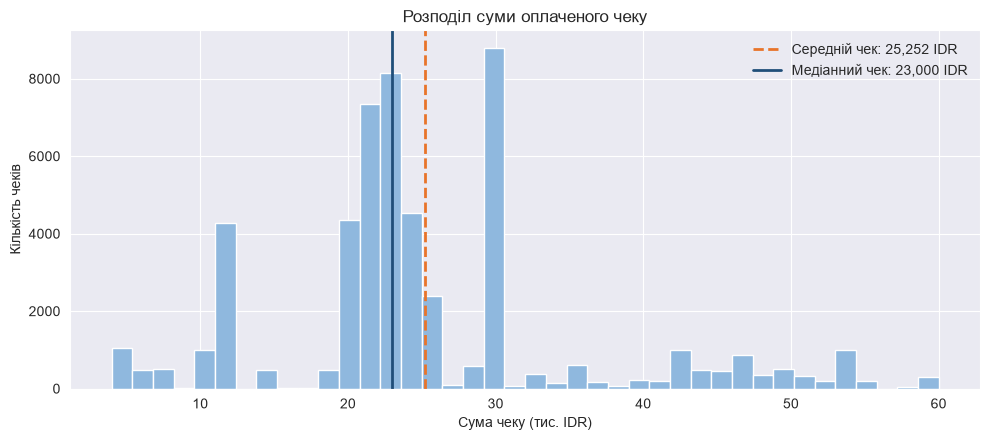

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.hist(paid['TotalAmount'] / 1000, bins=40, color=LIGHT_BLUE, edgecolor='white')
ax.axvline(avg_check_paid / 1000, color=ORANGE, linewidth=2, linestyle='--', label=f'Середній чек: {avg_check_paid:,.0f} IDR')
ax.axvline(median_check_paid / 1000, color=BLUE, linewidth=2, label=f'Медіанний чек: {median_check_paid:,.0f} IDR')

ax.set_title('Розподіл суми оплаченого чеку')
ax.set_xlabel('Сума чеку (тис. IDR)')
ax.set_ylabel('Кількість чеків')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Висновок:** гістограма показує, скільки чеків припадає на кожну суму. Високі стовпчики відповідають цінам популярних напоїв, а правий «хвіст» це чеки з двома позиціями. Середній і медіанний чек близькі, тож «типовий» клієнт витрачає приблизно 23–25 тис. IDR (один напій).

## 5. Порівняння торгових точок
Скільки заробляє кожен заклад і чи відрізняється середній чек?

In [24]:
outlet_df = transactions.groupby('Outlet').agg(
    Receipts=('ReceiptNumber', 'count'),
    Items_Sold=('TotalItem', 'sum'),
    Revenue=('TotalAmount', 'sum')
).sort_values('Revenue', ascending=False)

outlet_df['Avg_Check_Paid'] = paid.groupby('Outlet')['TotalAmount'].mean()
outlet_df['Revenue_Share_%'] = outlet_df['Revenue'] / total_revenue * 100

display(outlet_df)

,Receipts,Items_Sold,Revenue,Avg_Check_Paid,Revenue_Share_%
Outlet,,,,,
SHOP001,26250,30249,644108000,25274.004316,48.971319
SHOP003,16753,19341,409504000,25292.075845,31.134454
SHOP002,10817,12383,261664000,25133.416579,19.894228


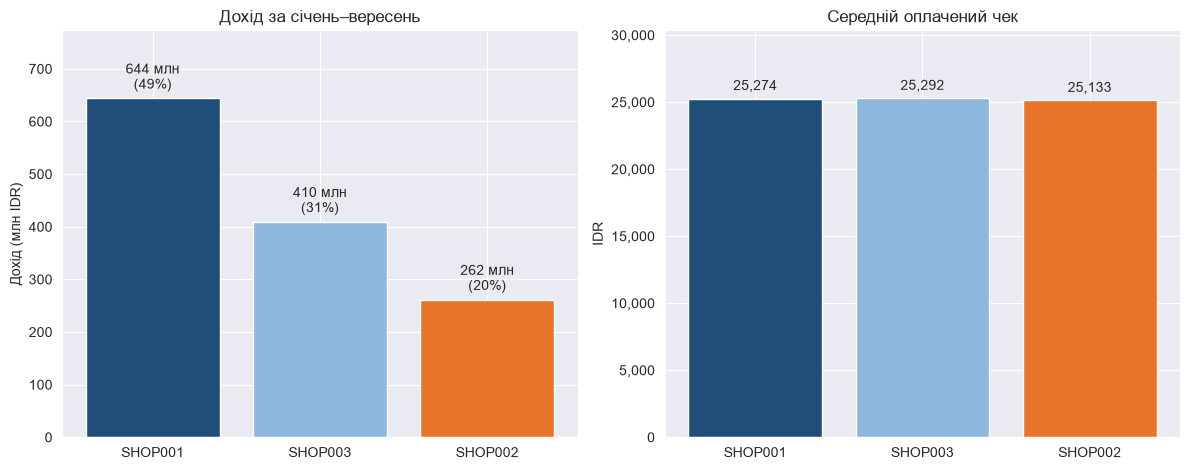

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
colors = [OUTLET_COLORS[o] for o in outlet_df.index]

# зліва: дохід
bars = ax1.bar(outlet_df.index, outlet_df['Revenue'] / 1e6, color=colors)
labels = [f'{r / 1e6:,.0f} млн\n({s:.0f}%)' for r, s in zip(outlet_df['Revenue'], outlet_df['Revenue_Share_%'])]
ax1.bar_label(bars, labels=labels, padding=4)
ax1.set_ylim(0, outlet_df['Revenue'].max() / 1e6 * 1.2)
ax1.set_title('Дохід за січень–вересень')
ax1.set_ylabel('Дохід (млн IDR)')

# справа: середній чек
bars = ax2.bar(outlet_df.index, outlet_df['Avg_Check_Paid'], color=colors)
ax2.bar_label(bars, labels=[f'{v:,.0f}' for v in outlet_df['Avg_Check_Paid']], padding=4)
ax2.set_ylim(0, outlet_df['Avg_Check_Paid'].max() * 1.2)
ax2.set_title('Середній оплачений чек')
ax2.set_ylabel('IDR')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))

plt.tight_layout()
plt.show()

**Висновок:**
- **SHOP001 приносить майже половину доходу мережі (≈49%)**, SHOP003 ≈31%, SHOP002 ≈20%.
- Середній чек у всіх трьох закладах майже однаковий (різниця менша за 2%). Отже, різниця в доході пояснюється **кількістю покупців**, а не тим, скільки вони витрачають.
- Щоб збільшити дохід SHOP002 і SHOP003, треба працювати з потоком гостей (локація, маркетинг, години роботи), а не з цінами.